# Mitotic cell division simulation


## How mitotic-spindle cell division works

In a real epithelium a dividing cell does not split along an arbitrary line: the
orientation of the cleavage plane is set by the **mitotic spindle**, a bipolar
microtubule structure that orients itself inside the cell before cytokinesis. This
notebook reproduces that mechanism on a VertAX `BoundedMesh` in three stages — find the
spindle, cut along it, then relax the new tissue — and then chains them into a lineage of
successive divisions.

### 1. Finding the spindle — `spindle_model.find_spindle`

The spindle is modelled as **two centrosomes** held a fixed distance apart (a fraction
`d_fraction` of the cell's mean radius), connected to the cell cortex by **microtubules**.
Each microtubule pulls with a force proportional to the local **edge tension**
$\Lambda_k$ **and to a power $L^{\beta}$ of its length** $L(\theta)$ (distance from the
centrosome to the cortex), $\mathrm{d}\mathbf{F}=\Lambda_k\,L^{\beta}\,\hat{\mathbf{e}}\,\mathrm{d}\theta$:
high-tension junctions pull harder, and the exponent $\beta$ tunes how strongly long
microtubules dominate (spindle polarity). The cortical pull is integrated along every edge with
Gauss–Legendre quadrature (`n_gauss` points, via `_centrosome_force_jax`). The spindle
settles where the **net force and net torque on the two centrosomes vanish**:

$$F_1 + F_2 = 0, \qquad M_1 + M_2 = 0.$$

`find_spindle` returns the spindle **centre** `c` and **axis** `u`. Three strategies are
available through `method`:

- **`'newton'`** (default) — Newton–Raphson on the full force/torque balance;
  deterministic, and the centre may drift from the centroid.
- **`'pdf'`** — treats orientation as a Boltzmann-like density
  $p(\alpha)\propto\exp(-\bar V(\alpha)/C)$ and takes its **mode** (most probable angle).
- **`'pdf_sample'`** — draws a **random** orientation from that same density, modelling the
  experimental variability; `C` sets the noise level.

The microtubule density can additionally be biased by **cell polarity**
$\Lambda(\theta)=\sigma_j\,(1+p\cos^2(\theta-\varphi))$, so a polarised cell preferentially
orients its spindle along its polarity axis $\varphi$. (The PDF and polarity variants are
detailed in their own sections further down.)

### 2. Cutting the cell — `cell_division.divide_cell`

Given the spindle axis `u`, `divide_cell(mesh, face_id, c, u)` performs the **half-edge
topology surgery**: it intersects the cleavage line (perpendicular to the spindle axis,
as in real cytokinesis) with the cell boundary, inserts two new vertices at the crossings
plus a new edge between them, and rewires the half-edge table so one cell becomes two. It
returns the new mesh (one extra face) and the index of the new daughter cell.

### 3. Relaxing the tissue — `energy_adaptive` + `BoundedBilevelOptimizer`

Just after the cut the daughter cells are not mechanically balanced. We relax the mesh
with the standard bilevel optimizer (`inner_optimization`), minimising `energy_adaptive`
— which drives every cell toward a shared **target area** (total area ÷ number of cells)
while tension shortens edges — with **T1 transitions enabled** so neighbour exchanges can
occur as the geometry settles.

Repeating these three steps yields a **lineage of divisions**; the sections below run 5
consecutive divisions with the deterministic, PDF, stochastic, and polarity-biased
spindle variants.

In [1]:
import importlib
import sys
import os
# Make the mitotic_spindle modules importable without a hard-coded path:
# use this notebook's own directory (falls back to CWD when __file__ is undefined).
_here = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
if _here not in sys.path:
    sys.path.insert(0, _here)
# Force the GPU backend (jax auto-selects it too, but this makes it explicit and
# fails loudly instead of silently falling back to CPU). Set to 'cpu' to force CPU.
os.environ.setdefault('JAX_PLATFORMS', 'cuda')
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
os.environ.setdefault('JAX_ENABLE_X64', 'true')

# Run on GPU: jax[cuda12] is installed, but jax 0.4.35 crashes auto-detecting the
# CUDA path because the nvidia-cuda-nvcc-cu12 wheel is a namespace package
# (cuda_nvcc.__file__ is None). Setting CUDA_ROOT makes jax use it directly and
# skip the broken nvcc import. Points at the pip-installed nvcc dir (has bin/ptxas
# and nvvm/libdevice).
import sysconfig
_nvcc = os.path.join(sysconfig.get_paths()['purelib'], 'nvidia', 'cuda_nvcc')
if os.path.isdir(_nvcc):
    os.environ.setdefault('CUDA_ROOT', _nvcc)

# The inline backend crops figures with bbox_inches='tight' by default, which
# leaves a blank band above figures that use manually-placed axes (e.g. the
# side-by-side spindle plot). Disable that cropping so figures render as laid out.
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

import optax
import jax
print(jax.devices())
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from vertax import BoundedMesh, BoundedBilevelOptimizer, get_plot_mesh, nonlinear_cg
from vertax import EdgePlot, FacePlot, VertexPlot
from vertax.topo import update_T1_bounded

# Reload the local modules in DEPENDENCY ORDER (leaves first, dependents last).
# importlib.reload updates a module in place but does NOT rewrite references that
# other modules already imported by value (e.g. spindle_analysis did
# `from energy_adaptive import energy_adaptive` at its own load time). Reloading a
# dependency without then reloading its dependents would leave the dependents
# bound to the OLD function — which is how a stale energy_adaptive (no curvature
# penalty) could keep being used and crash divide_cell. Reloading in this order
# guarantees every module picks up the current source.
import mesh_utils;        importlib.reload(mesh_utils)
import energy_adaptive;   importlib.reload(energy_adaptive)
import cell_division;     importlib.reload(cell_division)
import spindle_model;     importlib.reload(spindle_model)
import visualization;     importlib.reload(visualization)
import spindle_analysis;  importlib.reload(spindle_analysis)

from mesh_utils import get_cell_segments
from spindle_model import find_spindle
from energy_adaptive import energy_adaptive
from cell_division import divide_cell
from visualization import _plot_spindle_pair

[CudaDevice(id=0)]


In [2]:
import math

n_cells = 20
width = math.sqrt(n_cells)
height = width

mesh = BoundedMesh.from_random_seeds(nb_seeds=n_cells, width=width, height=height, random_key=2)


## Initial mesh and relaxation

Set per-element parameters (edge tensions, target areas) on the freshly seeded mesh, then
relax it with the bilevel optimizer using an **SGD** inner solver. The mesh is snapshotted
just before relaxation so the result can be shown **before / after** side by side.

In [3]:
mesh.vertices_params = jnp.asarray([0.0 for _ in range(mesh.nb_vertices)])

key = jax.random.PRNGKey(3)
# Raw (unbounded) edge-tension parameters: the physical tension is
# sigmoid(edges_params) + 1 in [1, 2], applied once by energy_adaptive and the
# plots. Storing raw values in [-4, 4] makes that tension span ~[1.02, 1.98], a
# balanced spread around 1.5 (do NOT pre-apply the sigmoid, or it is squashed twice).
mesh.edges_params = jax.random.uniform(key, (mesh.nb_edges,)) * 8 - 4

mesh.faces_params = jnp.asarray([0.6 for _ in range(mesh.nb_faces)])


In [4]:
# Snapshot of the mesh BEFORE relaxation (for the before/after comparison plot).
mesh_initial = BoundedMesh.copy_mesh(mesh)

# Fix the common 'Area of cell' colour scale (used by every mesh plot in the
# notebook) to the raw initial mesh's area range.
import visualization
_init_areas = mesh_initial.get_area(jnp.arange(mesh_initial.nb_faces))
visualization.set_area_scale(float(_init_areas.min()), float(_init_areas.max()))

bilevel_optimizer = BoundedBilevelOptimizer()
bilevel_optimizer.loss_function_inner = energy_adaptive
bilevel_optimizer.inner_solver        = nonlinear_cg(restart_every=10)
#   optax.sgd(learning_rate=1e-3)        # plain gradient descent
#   optax.adam(learning_rate=1e-3)       # adaptive first-order
#   nonlinear_cg(restart_every=10)       # conjugate gradient (Polak-Ribiere + line search)
#   optax.lbfgs()                        # limited-memory quasi-Newton (line search)
bilevel_optimizer.update_T1           = True
bilevel_optimizer._update_T1_func     = update_T1_bounded
bilevel_optimizer.min_dist_T1         = 0.01
bilevel_optimizer.max_nb_iterations   = 1000
bilevel_optimizer.tolerance           = 1e-6
bilevel_optimizer.patience            = 50

loss_history = bilevel_optimizer.inner_optimization(mesh)

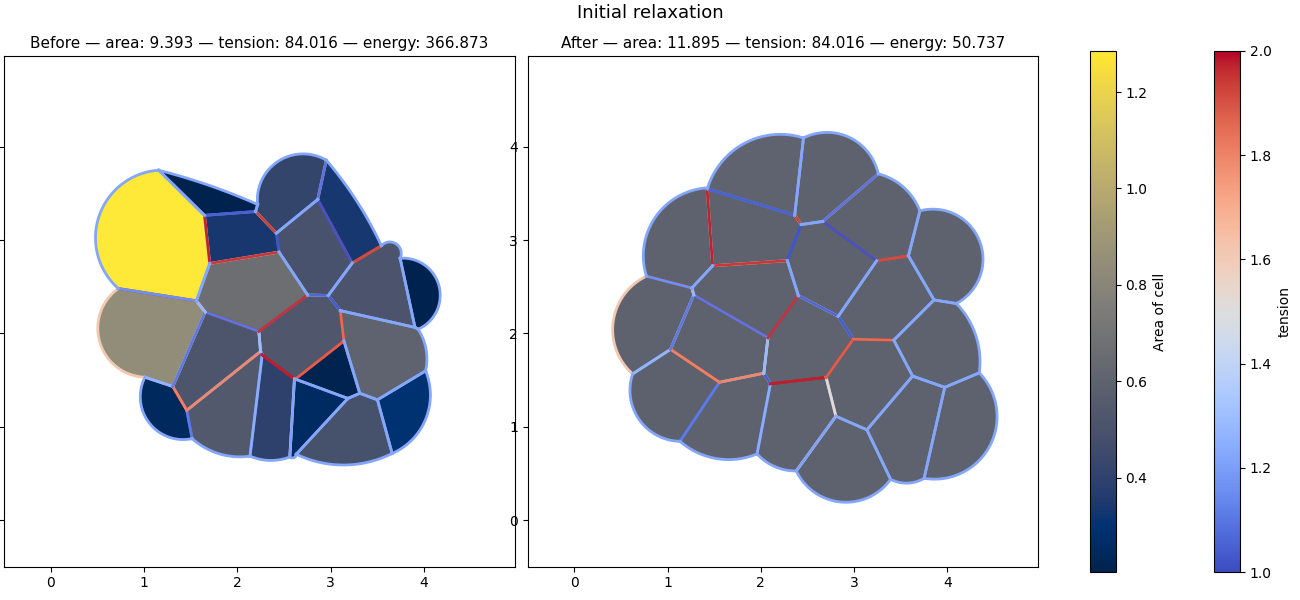

In [5]:
import matplotlib
from visualization import _draw_mesh_on_ax, AREA_SCALE, TENSION_SCALE
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

area_before = float(jnp.sum(mesh_initial.get_area(jnp.arange(mesh_initial.nb_faces))))
area_after  = float(jnp.sum(mesh.get_area(jnp.arange(mesh.nb_faces))))

# Total physical tension = sum over edges of sigmoid(edges_params) + 1 (same
# transform as energy_adaptive); edges_params is the raw, unbounded parameter.
tension_before = float(jnp.sum(jax.nn.sigmoid(mesh_initial.edges_params) + 1.0))
tension_after  = float(jnp.sum(jax.nn.sigmoid(mesh.edges_params) + 1.0))

def _energy(m):
    """Total adaptive energy of a mesh (same energy that is minimised)."""
    return float(energy_adaptive(
        jnp.asarray(m.vertices), jnp.asarray(m.angles), jnp.asarray(m.edges),
        jnp.asarray(m.faces), None, None, None,
        jnp.asarray(m.vertices_params), jnp.asarray(m.edges_params),
        jnp.asarray(m.faces_params)))

energy_before = _energy(mesh_initial)
energy_after  = _energy(mesh)

# Both meshes are drawn directly into a shared (1, 2) grid. _draw_mesh_on_ax sets
# identical axis limits ([-0.5, width+0.5] x [-0.5, height+0.5]) and equal aspect
# on every panel, so the two frames have exactly the same size and scale.
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
fig.suptitle("Initial relaxation", fontsize=13)

_draw_mesh_on_ax(mesh_initial, axes[0], AREA_SCALE, TENSION_SCALE)
axes[0].set_title(f"Before — area: {area_before:.3f} — tension: {tension_before:.3f} — energy: {energy_before:.3f}", fontsize=11)

_draw_mesh_on_ax(mesh, axes[1], AREA_SCALE, TENSION_SCALE)
axes[1].set_title(f"After — area: {area_after:.3f} — tension: {tension_after:.3f} — energy: {energy_after:.3f}", fontsize=11)

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE), matplotlib.colormaps["cividis"])
fig.colorbar(sm_tension, ax=axes, label="tension")
fig.colorbar(sm_area, ax=axes, label="Area of cell")
plt.show()

## Mitotic spindle


In [6]:
import importlib
import spindle_model; importlib.reload(spindle_model)
import cell_division; importlib.reload(cell_division)
from spindle_model import find_spindle
from cell_division import divide_cell

# Pick the cell to divide (find_spindle always returns an axis, falling back to
# the geometric centroid when Newton does not converge, so any cell is divisible).
import numpy as np
from mesh_utils import get_cell_segments
rng = np.random.default_rng(0)
face_id = int(rng.permutation(mesh.nb_faces)[0])
v0s, v1s, tensions = get_cell_segments(face_id, mesh)
c, u, c1, c2 = find_spindle(face_id, mesh, d_fraction=0.3, n_gauss=12)

print(f"Selected cell: {face_id}")
print(f"Center: ({c[0]:.4f}, {c[1]:.4f})")
print(f"Spindle axis u: ({u[0]:.4f}, {u[1]:.4f})")


Cell 4 — spindle (fallback to geometric centroid: not converged (|R|=1.5e-06))
  Center    : (2.3639, 1.0555)
  Axis u    : (-0.8944, -0.4472)
Selected cell: 4
Center: (2.3639, 1.0555)
Spindle axis u: (-0.8944, -0.4472)


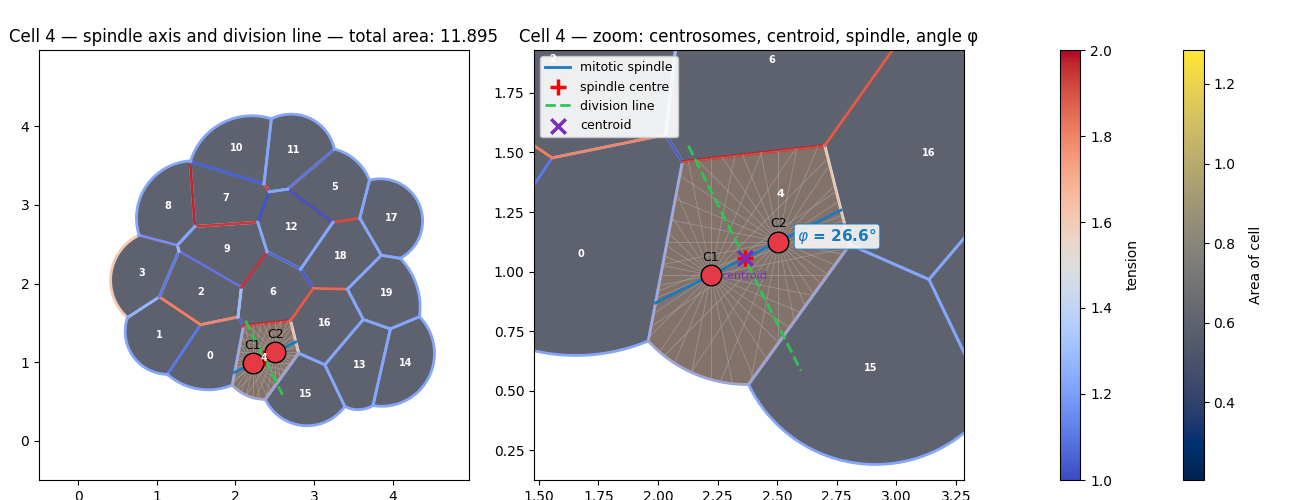

In [7]:
from visualization import _plot_spindle_pair
# Two views: the classic full-tissue plot, and a zoom on the dividing cell
# showing the two centrosomes (C1, C2), the geometric centroid, the mitotic
# spindle axis, and the angle φ.
_plot_spindle_pair(mesh, face_id, c, u, c1, c2, v0s, v1s)
plt.show()

## Cell division and relaxation

Cut the selected cell along the spindle axis, then relax the tissue with the bilevel
inner optimization. The mesh is shown **just after division** (left) and **after
relaxation** (right), side by side.

In [8]:
mesh_post, _ = divide_cell(mesh, face_id, c, u)

print(f"Before: {mesh.nb_faces} cells")
print(f"After: {mesh_post.nb_faces} cells")

Before: 20 cells
After: 21 cells


In [ ]:
mesh_opt = BoundedMesh.copy_mesh(mesh_post)
# Fixed per-cell target area: every cell relaxes towards 0.6 (no total-area target),
# so the tissue's total area grows as cells divide.
target_area = 0.6
mesh_opt.faces_params = jnp.full(mesh_opt.nb_faces, target_area)
print(f"Per-cell target area: {target_area:.4f} ({mesh_opt.nb_faces} cells "
      f"→ total target {target_area * mesh_opt.nb_faces:.4f})")

opt = BoundedBilevelOptimizer()
opt.loss_function_inner = energy_adaptive
opt.inner_solver        = nonlinear_cg(restart_every=10)
opt.update_T1           = True
opt._update_T1_func     = update_T1_bounded
opt.min_dist_T1         = 0.01
opt.max_nb_iterations   = 1000
opt.tolerance           = 1e-6
opt.patience            = 50

print(f"Before: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
loss_hist = opt.inner_optimization(mesh_opt)
print(f"After: {mesh_opt.nb_faces} cells, {mesh_opt.nb_edges} edges")
print(f"{len(loss_hist)} iterations, loss = {float(loss_hist[-1]):.4f}")

Per-cell target area: 0.6000 (21 cells → total target 12.6000)
Before: 21 cells, 60 edges
After: 21 cells, 60 edges
1000 iterations, loss = 53.8671


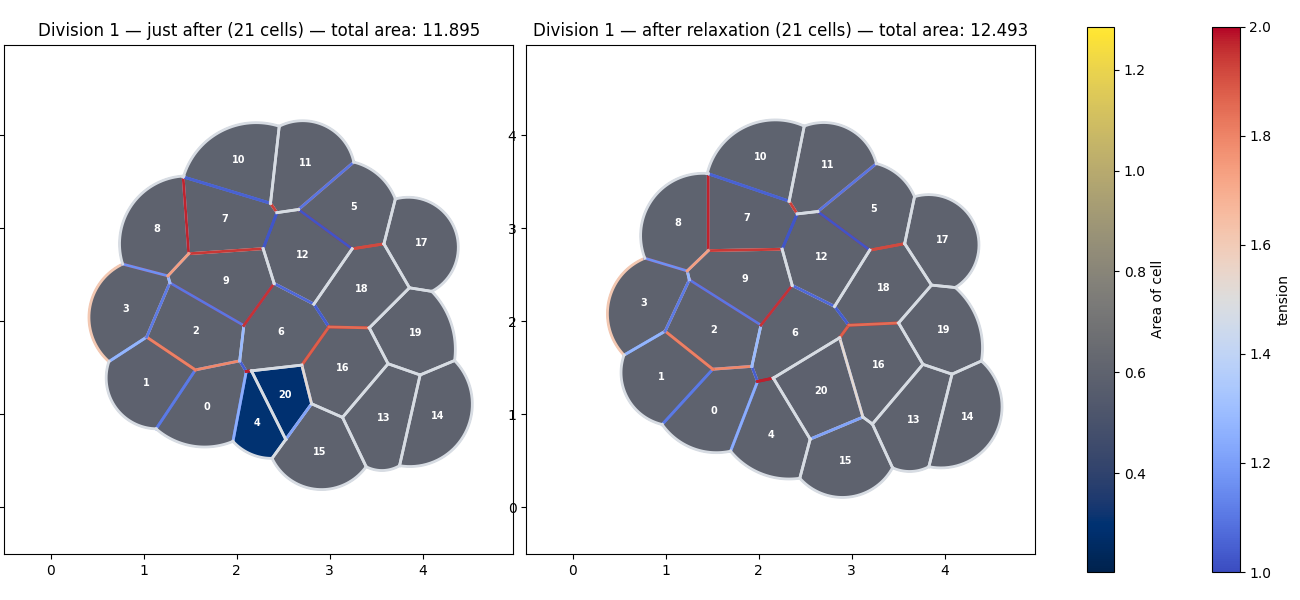

In [10]:
from visualization import _plot_div_relax_pair
# Left: mesh just after division.  Right: mesh after relaxation (inner optimization).
# Colour scales are taken from `mesh_initial` (the raw initial mesh, same scale as the
# "before relaxation" panel) so the areas/tensions are comparable across the notebook.
_plot_div_relax_pair(mesh_post, mesh_opt, division_idx=1, mesh_ref=mesh_initial)
plt.show()

## The per-edge arc angle $\alpha$

Boundary edges of a `BoundedMesh` are **circular arcs**, not straight segments — they
model the curved cell membrane. Each edge stores a single number $\alpha$ in
`mesh.angles` (one per edge, **not** an angle between two edges): it is the **half
central angle** of that edge's arc, i.e. half the angle subtended at the centre of the
supporting circle by the two endpoints $p_1, p_2$.

The arc radius is $r = \dfrac{\lVert p_2-p_1\rVert}{2\sin\alpha}$, so:

- $\alpha = 0^\circ$ — the arc is **flat**: a straight edge (zero curvature);
- $\alpha = 45^\circ$ — a moderate bulge; the circle centre sits well off the chord;
- $\alpha = 90^\circ$ — the arc is a **half-circle**: the chord becomes the diameter and
  the circle centre falls **exactly on the chord** ($h=0$). This is geometrically
  degenerate — `divide_cell` relies on the centre being clearly on one side of the chord
  to decide whether a cut point lies on the arc, so a half-circle edge has **no valid
  cut** and division fails. It is also non-physical: a real membrane never folds into a
  half-circle.

The plot below shows the three cases for one edge $p_1\!-\!p_2$.

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt


def _edge_arc(alpha, p1, p2, n=80):
    """Circular arc of an edge with half-central-angle `alpha`, same construction as
    vertax' bounded geometry. Returns (center, radius, h, arc_polyline). center is
    None and the polyline is the straight chord when alpha == 0."""
    p1 = np.asarray(p1, float); p2 = np.asarray(p2, float)
    v = p2 - p1; L = np.linalg.norm(v); half = L / 2
    m = 0.5 * (p1 + p2); perp = np.array([-v[1], v[0]]) / L
    if alpha < 1e-9:
        return None, np.inf, 0.0, np.vstack([p1, p2])
    r = half / np.sin(alpha)                 # arc radius
    h = math.sqrt(max(r**2 - half**2, 0.0))  # center-to-chord distance
    center = m + perp * h
    a1 = math.atan2(*(p1 - center)[::-1]); a2 = math.atan2(*(p2 - center)[::-1])
    if abs(a2 - a1) > math.pi:               # take the minor arc
        if a1 < a2: a1 += 2 * math.pi
        else:       a2 += 2 * math.pi
    ts = np.linspace(a1, a2, n)
    arc = np.column_stack([center[0] + r * np.cos(ts), center[1] + r * np.sin(ts)])
    return center, r, h, arc


p1, p2 = np.array([0.0, 0.0]), np.array([2.0, 0.0])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, deg in zip(axes, [0, 45, 90]):
    center, r, h, arc = _edge_arc(math.radians(deg), p1, p2)
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], "k--", lw=1.2, label="chord  p1-p2", zorder=2)
    ax.plot(arc[:, 0], arc[:, 1], color="C0", lw=3, label="arc (membrane)", zorder=3)
    ax.plot(*p1, "ko", ms=7, zorder=4); ax.plot(*p2, "ko", ms=7, zorder=4)
    ax.annotate("p1", p1, textcoords="offset points", xytext=(-14, -14), fontsize=10)
    ax.annotate("p2", p2, textcoords="offset points", xytext=(6, -14), fontsize=10)
    sub = f"central angle 2a = {2 * deg} deg"
    if center is not None:
        ax.plot([center[0], p1[0]], [center[1], p1[1]], color="C3", lw=1.2, zorder=2)
        ax.plot([center[0], p2[0]], [center[1], p2[1]], color="C3", lw=1.2, zorder=2)
        ax.plot(*center, "s", color="C3", ms=9, label="circle center", zorder=4)
        ax.annotate("center", center, textcoords="offset points",
                    xytext=(6, 8), color="C3", fontsize=9)
    else:
        sub = "straight edge (no curvature)"
    if deg == 90:
        sub += "\nhalf-circle - center ON the chord (h=0) -> divide_cell fails"
        ax.annotate("h = 0", (1.0, 0.0), textcoords="offset points", xytext=(0, -22),
                    color="C3", fontsize=10, ha="center", fontweight="bold")
    ax.set_title(f"a = {deg} deg\n{sub}", fontsize=10)
    ax.set_xlim(-0.6, 2.6); ax.set_ylim(-0.9, 1.4)
    ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower center")

fig.suptitle("Edge arc geometry - a is the half central angle of a SINGLE edge "
             "(0 deg = straight, 90 deg = half-circle)", fontsize=12)
plt.tight_layout()
plt.show()

## 5 consecutive divisions


In [11]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions
from vertax import nonlinear_cg

# === knobs ========================================================================
DIVISION_METHOD = "standard"   # "standard" | "thery" | "pcp" | "edge_score"
INNER_SOLVER    = nonlinear_cg(restart_every=10)
#   optax.sgd(learning_rate=1e-3)        # plain gradient descent
#   optax.adam(learning_rate=1e-3)       # adaptive first-order
#   nonlinear_cg(restart_every=10)       # conjugate gradient (Polak-Ribiere + line search)
#   optax.lbfgs()                        # limited-memory quasi-Newton (line search)
N_DIVISIONS     = 5
# method-specific extras (used only by the matching method):
PDF_C             = 0.1   # "thery": noise level Θ of the orientation density
POLARITY_STRENGTH = 1.0   # "pcp":   how strongly the tension polarity biases the axis
EDGE_BIAS_KAPPA   = 4.0   # "edge_score": anchor on the Newton axis
EDGE_BIAS_BETA    = 2.0   # "edge_score": edge-score bias strength
# ==================================================================================

# Map the chosen division method to run_n_divisions' spindle parameters.
#   standard   -> deterministic Newton force/torque balance
#   thery      -> Théry et al. 2007 orientation density (stochastic sample)
#   pcp        -> Newton axis biased by the cell's tension-polarity axis
#   edge_score -> Newton axis biased probabilistically by per-edge polarity scores
_method_kwargs = {
    "standard":   dict(spindle_method="newton"),
    "thery":      dict(spindle_method="pdf_sample", spindle_pdf_C=PDF_C,
                       spindle_rng=np.random.default_rng(1)),
    "pcp":        dict(spindle_method="newton", polarity_strength=POLARITY_STRENGTH),
    "edge_score": dict(spindle_method="newton", edge_bias=True,
                       edge_bias_kappa=EDGE_BIAS_KAPPA, edge_bias_beta=EDGE_BIAS_BETA,
                       edge_bias_rng=np.random.default_rng(2)),
}
if DIVISION_METHOD not in _method_kwargs:
    raise ValueError(f"Unknown DIVISION_METHOD {DIVISION_METHOD!r}; "
                     f"choose from {list(_method_kwargs)}")

mesh_newton = BoundedMesh.copy_mesh(mesh)
mesh_final, division_snapshots = run_n_divisions(
    mesh_newton, n_divisions=N_DIVISIONS,
    cell_rng=np.random.default_rng(0),
    inner_solver=INNER_SOLVER,
    **_method_kwargs[DIVISION_METHOD],
)
print(f"method={DIVISION_METHOD}: final tissue {mesh_final.nb_faces} cells, "
      f"{mesh_final.nb_edges} edges")


Division 1/5
Cell 4 — spindle (fallback to geometric centroid: not converged (|R|=1.5e-06))
  Center    : (2.3639, 1.0555)
  Axis u    : (-0.8944, -0.4472)
Selected cell: 4
  Areas — min: 0.2890, max: 0.5978, NaN: 0
Per-cell target area: 0.6000 (21 cells → total target 12.6000)
Optimization: 2000 iter, loss 89.0932 → 53.8103

Division 2/5
Cell 19 — spindle (fallback to geometric centroid: not converged (|R|=4.9e-02))
  Center    : (4.0071, 1.9134)
  Axis u    : (-0.8574, 0.5146)
Selected cell: 19
  Areas — min: 0.2932, max: 0.5981, NaN: 0
Per-cell target area: 0.6000 (22 cells → total target 13.2000)
Optimization: 2000 iter, loss 92.2332 → 56.5642

Division 3/5
Cell 7 — spindle (newton)
  Residual  : 4.24e-08
  Center    : (2.2443, 2.9275)
  Axis u    : (-0.4854, -0.8743)
Selected cell: 7
  Areas — min: 0.2848, max: 0.5982, NaN: 0
Per-cell target area: 0.6000 (23 cells → total target 13.8000)
Optimization: 1649 iter, loss 94.8174 → 58.9371

Division 4/5
Cell 10 — spindle (newton)
  Re

In [ ]:
from visualization import (_draw_mesh_on_ax, _add_cell_labels,
                           AREA_SCALE, TENSION_SCALE)
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area = ScalarMappable(Normalize(*AREA_SCALE), matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    """Add a tension + area colorbar pair to the right of one grid row. Labels are
    put on the LEFT of each bar so they never collide with the neighbouring bar."""
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area, ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.set_label(lbl)


n_rows = len(division_snapshots)
fig, axes = plt.subplots(n_rows, 2, figsize=(16, 5 * n_rows))
axes = np.atleast_2d(axes)  # keep 2-D indexing when n_rows == 1
fig.suptitle(f"{n_rows} divisions ({DIVISION_METHOD})  |  "
             f"left: just after division  ·  right: after relaxation",
             fontsize=13)

for div_idx, (snap_post, snap_opt) in enumerate(division_snapshots, start=1):
    row = div_idx - 1
    for col, (snap, label) in enumerate([
            (snap_post, f"Division {div_idx} — just after ({snap_post.nb_faces} cells)"),
            (snap_opt,  f"Division {div_idx} — after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        # Common scales (tension = sigmoid(he_params)+1 ∈ [1,2]; area = initial mesh).
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} — area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

## Comparison of division methods — post-division (pre-relaxation)

Each row is one division step (same cell chosen at each step across all methods,
`cell_rng=rng(0)`). The columns show the tissue **just after the cut**, before
any relaxation, for each division method — the same names and knobs as the
**5 consecutive divisions** section:

| Column | Method | Spindle model |
|--------|--------|---------------|
| 1 | `standard`   | Newton (deterministic force/torque balance) |
| 2 | `thery`      | Théry et al. 2007 orientation density (stochastic sample) |
| 3 | `pcp`        | Newton axis biased by the cell's tension-polarity axis (p = 1.0) |
| 4 | `edge_score` | Newton axis biased by per-edge polarity scores |

Set `COMPARE_METHODS`, `INNER_SOLVER`, `N_DIVISIONS` and the per-method knobs
(`PDF_C`, `POLARITY_STRENGTH`, `EDGE_BIAS_KAPPA`, `EDGE_BIAS_BETA`) in the cell below.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions
from vertax import nonlinear_cg
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# === knobs (same names/methods as the "5 consecutive divisions" section) ==========
COMPARE_METHODS = ["standard", "thery", "pcp", "edge_score"]
INNER_SOLVER    = nonlinear_cg(restart_every=10)   # same options as 5-consecutive
N_DIVISIONS     = 5
PDF_C             = 0.1   # "thery"
POLARITY_STRENGTH = 1.0   # "pcp"
EDGE_BIAS_KAPPA   = 4.0   # "edge_score"
EDGE_BIAS_BETA    = 2.0   # "edge_score"
# ==================================================================================

# Same method -> run_n_divisions mapping as the 5-consecutive-divisions cell.
def _method_kwargs(method):
    return {
        "standard":   dict(spindle_method="newton"),
        "thery":      dict(spindle_method="pdf_sample", spindle_pdf_C=PDF_C,
                           spindle_rng=np.random.default_rng(1)),
        "pcp":        dict(spindle_method="newton", polarity_strength=POLARITY_STRENGTH),
        "edge_score": dict(spindle_method="newton", edge_bias=True,
                           edge_bias_kappa=EDGE_BIAS_KAPPA, edge_bias_beta=EDGE_BIAS_BETA,
                           edge_bias_rng=np.random.default_rng(2)),
    }[method]

# Run every method from the SAME initial mesh; cell_rng=rng(0) each time so the same
# cell is chosen at each division step across all methods.
method_snapshots = []
for method in COMPARE_METHODS:
    m = BoundedMesh.copy_mesh(mesh)
    _, snaps = run_n_divisions(
        m, n_divisions=N_DIVISIONS,
        cell_rng=np.random.default_rng(0),
        inner_solver=INNER_SOLVER,
        **_method_kwargs(method),
    )
    method_snapshots.append((snaps, method))

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE),    matplotlib.colormaps["cividis"])


def _row_colorbars5(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.012, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area,    ax=row_axes, fraction=0.012, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.set_label(lbl)


n_divs = min(len(s) for s, _ in method_snapshots)
ncol = len(method_snapshots)
fig, axes = plt.subplots(n_divs, ncol, figsize=(7 * ncol, 5 * n_divs))
axes = np.atleast_2d(axes)
fig.suptitle(
    "Division methods — post-division, pre-relaxation  |  cols: "
    + " · ".join(COMPARE_METHODS),
    fontsize=12,
)

for row in range(n_divs):
    for col, (snaps, method_name) in enumerate(method_snapshots):
        snap_post, _ = snaps[row]
        ax = axes[row, col]
        ta = float(jnp.sum(snap_post.get_area(jnp.arange(snap_post.nb_faces))))
        _draw_mesh_on_ax(snap_post, ax, AREA_SCALE, TENSION_SCALE)
        _add_cell_labels(ax, snap_post)
        ax.set_title(f"Div {row + 1} — {method_name} ({snap_post.nb_faces}c) — area: {ta:.3f}",
                     fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars5(fig, axes[row, :])

plt.show()

## Inner-solver benchmark — which solver relaxes fastest over 25 divisions

The mechanical relaxation after each division is an inner optimization
(`BoundedBilevelOptimizer.inner_optimization`) that minimises `energy_adaptive`.
Here we compare four optax-compatible inner solvers on the **same** division
sequence — a **4-cell** bounded mesh subjected to **25 consecutive divisions**
(ending at 29 cells) — and measure the **wall-clock time** of each full run.

| Solver | Construction | Kind |
|--------|--------------|------|
| **SGD**    | `optax.sgd(learning_rate=1e-3)` | plain gradient descent |
| **Adam**   | `optax.adam(learning_rate=1e-3)` | adaptive first-order |
| **CG**     | `vertax.nonlinear_cg(restart_every=10)` | nonlinear conjugate gradient (Polak–Ribière + zoom line search) |
| **L-BFGS** | `optax.lbfgs()` | limited-memory quasi-Newton (zoom line search) |

Everything else is held fixed: same starting mesh, same `cell_rng(0)` (so each
solver picks the **same** cells and division axes at every step), same
`energy_adaptive`, same T1 settings, same `max_opt_iter`. Only `inner_solver`
changes, via the `inner_solver=` argument of `run_n_divisions`.

Each solver runs in its **own cell** so its timing is recorded independently;
the final cells plot the **initial** and **final** mesh per solver and summarise
the timings.

> **Note** — `optax.lbfgs` requires **optax ≥ 0.2.5** here: in 0.2.4 its zoom
> line-search state mixes `int32`/`int64`, which breaks the early-stopping
> `lax.cond` inside `inner_optimization` under `JAX_ENABLE_X64`. The project pins
> `optax==0.2.5`.

In [ ]:
# --- Self-contained setup: works even if run right after a kernel restart -------
# jax 0.4.35 crashes auto-detecting the CUDA path (cuda_nvcc.__file__ is None), so
# CUDA_ROOT must be set BEFORE the first `import jax`. The notebook's top imports
# cell already does this; we repeat it here so this benchmark section is runnable
# on its own without hitting the misleading "partially initialized jax" error.
import os, sys, math, sysconfig
_here = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
if _here not in sys.path:
    sys.path.insert(0, _here)
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')
os.environ.setdefault('JAX_ENABLE_X64', 'true')
_nvcc = os.path.join(sysconfig.get_paths()['purelib'], 'nvidia', 'cuda_nvcc')
if os.path.isdir(_nvcc):
    os.environ.setdefault('CUDA_ROOT', _nvcc)

import time
import importlib
import numpy as np
import jax
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt

from vertax import BoundedMesh, nonlinear_cg
import energy_adaptive as _ea_mod; importlib.reload(_ea_mod)
from energy_adaptive import energy_adaptive
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions

# Benchmark settings: a small 4-cell tissue (minimum for a Voronoi mesh) taken
# through 25 consecutive divisions -> 29 cells. Each solver gets its OWN iteration
# budget and early-stopping criterion, passed explicitly in its cell below.
BENCH_N_CELLS    = 4
BENCH_N_DIV      = 25
BENCH_TARGET_AREA = 0.6
# Default early-stopping criterion (per solver cell may override).
BENCH_TOLERANCE  = 1e-4
BENCH_PATIENCE   = 5


def mesh_metrics(m):
    """Energy decomposition + area/tension stats of a relaxed mesh, computed with
    the SAME energy that is minimised (energy_adaptive). Returns a dict with the
    global energy, its area vs tension parts, and mean area / mean tension."""
    vt = jnp.asarray(m.vertices); at = jnp.asarray(m.angles)
    he = jnp.asarray(m.edges);    fc = jnp.asarray(m.faces)
    vp = jnp.asarray(m.vertices_params)
    ep = jnp.asarray(m.edges_params); fp = jnp.asarray(m.faces_params)

    E_total = float(energy_adaptive(vt, at, he, fc, None, None, None, vp, ep, fp))

    # Area part: K_AREAS * sum (area - target)^2 (target = fp[0]); tension part is
    # the remainder of the total (inner + surface edge energy).
    areas = m.get_area(jnp.arange(m.nb_faces))
    E_area = float(_ea_mod.K_AREAS * jnp.sum((areas - fp[0]) ** 2))
    E_tension = E_total - E_area
    tensions = jax.nn.sigmoid(ep) + 1
    return dict(E=E_total, E_area=E_area, E_tension=E_tension,
                mean_area=float(jnp.mean(areas)), total_area=float(jnp.sum(areas)),
                mean_tension=float(jnp.mean(tensions)))


def make_bench_mesh():
    """Fresh 4-cell bounded mesh with the same tension/area conventions used
    throughout this notebook (so every solver starts from an identical mesh)."""
    w = math.sqrt(BENCH_N_CELLS)
    m = BoundedMesh.from_random_seeds(nb_seeds=BENCH_N_CELLS, width=w, height=w, random_key=2)
    m.vertices_params = jnp.asarray([0.0 for _ in range(m.nb_vertices)])
    key = jax.random.PRNGKey(3)
    m.edges_params = jax.random.uniform(key, (m.nb_edges,)) * 8 - 4  # raw; tension = sigmoid+1
    m.faces_params = jnp.asarray([BENCH_TARGET_AREA for _ in range(m.nb_faces)])
    return m


def run_solver_benchmark(name, solver, max_iter,
                         tolerance=BENCH_TOLERANCE, patience=BENCH_PATIENCE):
    """Run the full 25-division sequence with `solver` as inner solver, `max_iter`
    inner iterations per relaxation, and the given early-stopping (tolerance,
    patience). Returns (elapsed_seconds, initial_mesh, final_mesh, params_dict).
    cell_rng is re-seeded to rng(0) so every solver divides the same cells along
    the same axes."""
    m0 = make_bench_mesh()
    m0_snapshot = BoundedMesh.copy_mesh(m0)
    iters_per_relax = []   # actual iterations of each per-division relaxation
    t0 = time.perf_counter()
    m_final, _ = run_n_divisions(
        m0, n_divisions=BENCH_N_DIV,
        cell_rng=np.random.default_rng(0),
        inner_solver=solver,
        max_opt_iter=max_iter,
        tolerance=tolerance,
        patience=patience,
        iters_out=iters_per_relax,
    )
    elapsed = time.perf_counter() - t0
    # Early stopping (tolerance + patience) means each relaxation usually runs
    # fewer than max_iter iterations; record the real per-relaxation counts.
    total_iters = int(sum(iters_per_relax))
    mean_iters  = total_iters / max(len(iters_per_relax), 1)
    params = dict(max_iter=max_iter, tolerance=tolerance, patience=patience,
                  iters_per_relax=iters_per_relax, total_iters=total_iters,
                  mean_iters=mean_iters)
    met = mesh_metrics(m_final)
    print(f"[{name}] {elapsed:.2f} s, {total_iters} iters total "
          f"({mean_iters:.0f}/relax, cap {max_iter}), tol={tolerance:g}, "
          f"patience={patience}  ->  {m_final.nb_faces} cells  "
          f"|  E={met['E']:.3f} (area {met['E_area']:.3f} + tension {met['E_tension']:.3f})")
    return elapsed, m0_snapshot, m_final, params


# Collected per-solver results: name -> (elapsed_s, initial_mesh, final_mesh, params).
bench_results = {}

In [ ]:
# --- SGD -------------------------------------------------------------------------
# Per-solver iteration budget + early-stopping criterion (edit freely).
SGD_MAX_ITER  = 2000
SGD_TOLERANCE = 1e-4
SGD_PATIENCE  = 5
bench_results["SGD"] = run_solver_benchmark(
    "SGD", optax.sgd(learning_rate=1e-3), SGD_MAX_ITER,
    tolerance=SGD_TOLERANCE, patience=SGD_PATIENCE)
sgd_time = bench_results["SGD"][0]
print(f"SGD total time: {sgd_time:.2f} s")

In [ ]:
# --- Adam ------------------------------------------------------------------------
ADAM_MAX_ITER  = 2000
ADAM_TOLERANCE = 1e-4
ADAM_PATIENCE  = 5
bench_results["Adam"] = run_solver_benchmark(
    "Adam", optax.adam(learning_rate=1e-3), ADAM_MAX_ITER,
    tolerance=ADAM_TOLERANCE, patience=ADAM_PATIENCE)
adam_time = bench_results["Adam"][0]
print(f"Adam total time: {adam_time:.2f} s")

In [ ]:
# --- CG (nonlinear conjugate gradient) -------------------------------------------
# Line-search solvers usually need far fewer iterations than plain SGD/Adam.
CG_MAX_ITER  = 2000
CG_TOLERANCE = 1e-4
CG_PATIENCE  = 5
bench_results["CG"] = run_solver_benchmark(
    "CG", nonlinear_cg(restart_every=10), CG_MAX_ITER,
    tolerance=CG_TOLERANCE, patience=CG_PATIENCE)
cg_time = bench_results["CG"][0]
print(f"CG total time: {cg_time:.2f} s")

In [ ]:
# --- L-BFGS (requires optax >= 0.2.5; see note above) ----------------------------
LBFGS_MAX_ITER  = 2000
LBFGS_TOLERANCE = 1e-4
LBFGS_PATIENCE  = 5
bench_results["L-BFGS"] = run_solver_benchmark(
    "L-BFGS", optax.lbfgs(), LBFGS_MAX_ITER,
    tolerance=LBFGS_TOLERANCE, patience=LBFGS_PATIENCE)
lbfgs_time = bench_results["L-BFGS"][0]
print(f"L-BFGS total time: {lbfgs_time:.2f} s")

In [ ]:
# Per-solver initial vs final mesh. One row per solver; left = initial 4-cell mesh,
# right = final mesh after 25 divisions. Edge colour = tension, cell colour = area.
# The final-mesh title reports the global energy and its area/tension split, the
# mean area and mean tension, the per-solver settings, and the wall-clock time.
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE),    matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area,    ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.set_label(lbl)


def _fit_axes_to_mesh(ax, mesh, margin=0.3):
    """Override the default width/height-based limits set by _draw_mesh_on_ax so the
    WHOLE tissue is visible: after 25 divisions the mesh grows past its initial
    width/height, so we fit the axes to the actual vertex extent (+ a small margin)."""
    v = np.asarray(mesh.vertices)
    xmin, ymin = v.min(axis=0); xmax, ymax = v.max(axis=0)
    ax.set_xlim(xmin - margin, xmax + margin)
    ax.set_ylim(ymin - margin, ymax + margin)


# Keep a stable solver order regardless of dict insertion.
solver_order = [n for n in ["SGD", "Adam", "CG", "L-BFGS"] if n in bench_results]
nrows = len(solver_order)

fig, axes = plt.subplots(nrows, 2, figsize=(17, 5.5 * nrows))
if nrows == 1:
    axes = axes[None, :]
fig.suptitle(f"Inner-solver benchmark — 4-cell mesh, {BENCH_N_DIV} divisions  "
             "|  left: initial  ·  right: final  (edge=tension, cell=area)", fontsize=13)

for row, name in enumerate(solver_order):
    elapsed, m_init, m_final, params = bench_results[name]
    mi = mesh_metrics(m_init)
    mf = mesh_metrics(m_final)
    settings = (f"{params['max_iter']} it/relax, tol={params['tolerance']:g}, "
                f"patience={params['patience']}, {elapsed:.1f} s")
    panels = [
        (m_init, mi,
         f"{name} — initial ({m_init.nb_faces} cells)\n"
         f"E={mi['E']:.2f} (area {mi['E_area']:.2f} + tension {mi['E_tension']:.2f})  ·  "
         f"areā={mi['mean_area']:.3f}  tension̄={mi['mean_tension']:.3f}"),
        (m_final, mf,
         f"{name} — final ({m_final.nb_faces} cells, {settings})\n"
         f"E={mf['E']:.2f} (area {mf['E_area']:.2f} + tension {mf['E_tension']:.2f})  ·  "
         f"areā={mf['mean_area']:.3f}  tension̄={mf['mean_tension']:.3f}"),
    ]
    for col, (snap, met, title) in enumerate(panels):
        ax = axes[row, col]
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _fit_axes_to_mesh(ax, snap)   # show the full contour (mesh grows past width/height)
        _add_cell_labels(ax, snap)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

In [ ]:
# Timing + quality summary — ranking from fastest to slowest over the 25-division run.
# Reports each solver's settings (iterations, tolerance, patience), wall-clock time,
# and the final mesh's global energy: fastest is not always lowest-energy.
ranked = sorted(bench_results.items(), key=lambda kv: kv[1][0])
fastest_name, (fastest_t, _, _, _) = ranked[0]

print(f"Inner-solver benchmark — 4-cell mesh, {BENCH_N_DIV} consecutive divisions")
print("-" * 104)
print(f"{'solver':8}  {'mean it':>7}  {'cap':>5}  {'tot it':>7}  {'tol':>7}  "
      f"{'patience':>8}  {'time (s)':>9}  {'vs fast':>8}  {'E_final':>9}")
for name, (elapsed, _, m_final, params) in ranked:
    mf = mesh_metrics(m_final)
    # mean it = real iterations per relaxation (early-stopped, usually < cap).
    print(f"{name:8}  {params['mean_iters']:>7.0f}  {params['max_iter']:>5}  "
          f"{params['total_iters']:>7}  {params['tolerance']:>7g}  "
          f"{params['patience']:>8}  {elapsed:>9.2f}  {elapsed / fastest_t:>7.2f}x  "
          f"{mf['E']:>9.2f}")
print("-" * 104)
print(f"Fastest: {fastest_name} ({fastest_t:.2f} s)")

# Two-panel summary: wall-clock time (left) and final global energy (right).
names = [n for n, _ in ranked]
times = [v[0] for _, v in ranked]
energies = [mesh_metrics(v[2])['E'] for _, v in ranked]
colors = ["#2a9d8f", "#457b9d", "#e9c46a", "#e76f51"][:len(names)]

fig, (ax_t, ax_e) = plt.subplots(1, 2, figsize=(14, 4.5))
fig.suptitle(f"Inner-solver benchmark — {BENCH_N_DIV} divisions on a 4-cell mesh", fontsize=13)

bars_t = ax_t.bar(names, times, color=colors)
ax_t.set_ylabel("wall-clock time (s)")
ax_t.set_title("Speed (lower is faster)")
for b, t in zip(bars_t, times):
    ax_t.text(b.get_x() + b.get_width() / 2, t, f"{t:.1f}s", ha="center", va="bottom", fontsize=9)

bars_e = ax_e.bar(names, energies, color=colors)
ax_e.set_ylabel("final global energy  E")
ax_e.set_title("Solution quality (lower energy = better relaxation)")
for b, e in zip(bars_e, energies):
    ax_e.text(b.get_x() + b.get_width() / 2, e, f"{e:.1f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## Parallel (simultaneous) divisions — N waves of M divisions

Instead of relaxing the tissue after *every* division (`run_n_divisions`), this
section divides **several cells at once per wave** and relaxes the tissue **once
per wave** (`run_n_divisions_parallel`). With `N_WAVES` waves of `N_PARALLEL`
simultaneous cuts, the tissue undergoes `N_WAVES * N_PARALLEL` divisions but only
`N_WAVES` relaxations — the relaxation being the dominant cost, this is ~2x
faster for the same number of divisions.

This is a **synchronous-mitosis** model: the cells of a wave are cut on the same
(un-relaxed) mesh, so the result differs from the sequential one — it is not just
a speed-up of the identical computation.

Set the two knobs below: `N_WAVES` (number of relaxation steps) and `N_PARALLEL`
(cells divided simultaneously in each wave).

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions_parallel

# Requires the inner-solver benchmark setup cell to have run first (it defines
# the imports, CUDA_ROOT, and make_bench_mesh()).

# === knobs: e.g. 5 waves of 5 simultaneous divisions = 25 divisions, 5 relaxations
N_WAVES    = 5
N_PARALLEL = 5

# Start from a fresh 4-cell mesh (same as the solver benchmark).
mesh_par = make_bench_mesh()
mesh_final_par, wave_snapshots = run_n_divisions_parallel(
    mesh_par, n_waves=N_WAVES, n_parallel=N_PARALLEL,
    cell_rng=np.random.default_rng(0),
)
print(f"After {N_WAVES} waves x {N_PARALLEL} divisions: {mesh_final_par.nb_faces} cells, "
      f"{mesh_final_par.nb_edges} edges  ({N_WAVES} relaxations)")

In [ ]:
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE
import matplotlib
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

sm_tension = ScalarMappable(Normalize(*TENSION_SCALE), matplotlib.colormaps["coolwarm"])
sm_area    = ScalarMappable(Normalize(*AREA_SCALE),    matplotlib.colormaps["cividis"])


def _row_colorbars(fig, row_axes):
    cbt = fig.colorbar(sm_tension, ax=row_axes, fraction=0.035, pad=0.03, aspect=15)
    cba = fig.colorbar(sm_area,    ax=row_axes, fraction=0.035, pad=0.07, aspect=15)
    for cb, lbl in ((cbt, "tension"), (cba, "Area of cell")):
        cb.set_label(lbl)


def _fit_axes_to_mesh(ax, m, margin=0.3):
    v = np.asarray(m.vertices)
    xmin, ymin = v.min(axis=0); xmax, ymax = v.max(axis=0)
    ax.set_xlim(xmin - margin, xmax + margin)
    ax.set_ylim(ymin - margin, ymax + margin)


fig, axes = plt.subplots(N_WAVES, 2, figsize=(16, 5 * N_WAVES))
if N_WAVES == 1:
    axes = axes[None, :]
fig.suptitle(f"{N_WAVES} waves x {N_PARALLEL} simultaneous divisions  "
             "|  left: just after the wave's cuts  .  right: after relaxation",
             fontsize=13)

for w, (snap_post, snap_opt) in enumerate(wave_snapshots, start=1):
    row = w - 1
    for col, (snap, label) in enumerate([
        (snap_post, f"Wave {w} - after cuts ({snap_post.nb_faces} cells)"),
        (snap_opt,  f"Wave {w} - after relaxation ({snap_opt.nb_faces} cells)"),
    ]):
        ax = axes[row, col]
        ta = float(jnp.sum(snap.get_area(jnp.arange(snap.nb_faces))))
        _draw_mesh_on_ax(snap, ax, AREA_SCALE, TENSION_SCALE)
        _fit_axes_to_mesh(ax, snap)
        _add_cell_labels(ax, snap)
        ax.set_title(f"{label} - area: {ta:.3f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    _row_colorbars(fig, axes[row, :])

plt.show()

## Animation — spindle set-up, parallel divisions, progressive relaxation

Each wave now has three phases, all animated:
1. **Spindle** — for every cell to divide, the exact spindle of the chosen method eases
   deterministically from a perturbed start (offset centre, random axis); the
   overlay shows the two **centrosomes** (green), the **centre** (red x) and the
   **cleavage line** (yellow dashed, ⟂ to the spindle axis).
2. **Cut** — every cell is divided at its settled (centre, axis).
3. **Relaxation** — the tissue relaxes once, sampled along the true trajectory.

Rendered to MP4 (ffmpeg via imageio-ffmpeg) and shown inline. Knobs in the run
cell: N_WAVES, N_PARALLEL, METHOD, SPINDLE_FRAMES, RELAX_FRAMES, START_OFFSET,
INNER_SOLVER. Requires the inner-solver benchmark setup cell to have run first.

In [ ]:
import importlib
import spindle_analysis; importlib.reload(spindle_analysis)
from spindle_analysis import run_n_divisions_parallel_animated

# === knobs: animate parallel (wave) divisions with a pre-division spindle phase ===
N_WAVES        = 5      # number of waves
N_PARALLEL     = 5      # cells divided simultaneously per wave
METHOD         = "newton"   # division method: "newton" | "thery" | "polarity" | "edge_score"
SPINDLE_FRAMES = 20     # frames of the (deterministic) spindle set-up before each cut
RELAX_FRAMES   = 10     # frames sampled along each relaxation
START_OFFSET   = 0.3    # initial spindle-centre offset (fraction of cell radius)
FORCE_BETA     = 3.0    # cortical-pull exponent: dF ∝ L^beta (1=linear, >1 long MTs dominate)
ANIM_MAX_ITER  = 1000   # max inner iterations per relaxation
INNER_SOLVER   = nonlinear_cg(restart_every=10) 
#   optax.sgd(learning_rate=1e-3)        # plain gradient descent
#   optax.adam(learning_rate=1e-3)       # adaptive first-order
#   nonlinear_cg(restart_every=10)       # conjugate gradient (Polak-Ribiere + line search)
#   optax.lbfgs()                        # limited-memory quasi-Newton (line search)
# Method extras (used by the matching method):
POLARITY_STRENGTH = 1.0   # 'polarity': how strongly the tension polarity biases the axis
EDGE_BIAS_KAPPA   = 4.0   # 'edge_score': anchor on the Newton axis
EDGE_BIAS_BETA    = 2.0   # 'edge_score': edge-score bias strength
# ==================================================================================

mesh_anim = make_bench_mesh()   # fresh 4-cell mesh (from the benchmark setup cell)
mesh_anim_final, anim_frames = run_n_divisions_parallel_animated(
    mesh_anim, n_waves=N_WAVES, n_parallel=N_PARALLEL, method=METHOD,
    spindle_frames=SPINDLE_FRAMES, relax_frames=RELAX_FRAMES,
    start_offset=START_OFFSET,
    polarity_strength=POLARITY_STRENGTH,
    edge_bias_kappa=EDGE_BIAS_KAPPA, edge_bias_beta=EDGE_BIAS_BETA,
    cell_rng=np.random.default_rng(0), spindle_rng=np.random.default_rng(1),
    edge_bias_rng=np.random.default_rng(2),
    inner_solver=INNER_SOLVER, max_opt_iter=ANIM_MAX_ITER,
    force_beta=FORCE_BETA,
)
n_spindle = sum(1 for f in anim_frames if f["kind"] == "spindle")
print(f"method={METHOD}: {len(anim_frames)} frames "
      f"({n_spindle} spindle + cuts + relax), final {mesh_anim_final.nb_faces} cells")

In [ ]:
import matplotlib
import imageio_ffmpeg
matplotlib.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from visualization import _draw_mesh_on_ax, _add_cell_labels, AREA_SCALE, TENSION_SCALE


# Fixed axes limits: large enough from the start to contain EVERY frame's mesh.
def _global_limits(frames, margin=0.4):
    xs_min = ys_min = np.inf
    xs_max = ys_max = -np.inf
    for fr in frames:
        v = np.asarray(fr['mesh'].vertices)
        xs_min = min(xs_min, v[:, 0].min()); xs_max = max(xs_max, v[:, 0].max())
        ys_min = min(ys_min, v[:, 1].min()); ys_max = max(ys_max, v[:, 1].max())
        for (c, alpha, d) in fr.get('spindles', []):
            u = np.array([np.cos(alpha), np.sin(alpha)])
            for p in (c + d * u, c - d * u):
                xs_min = min(xs_min, p[0]); xs_max = max(xs_max, p[0])
                ys_min = min(ys_min, p[1]); ys_max = max(ys_max, p[1])
    return (xs_min - margin, xs_max + margin, ys_min - margin, ys_max + margin)


XMIN, XMAX, YMIN, YMAX = _global_limits(anim_frames)


def _draw_spindles(ax, spindles):
    for (c, alpha, d) in spindles:
        u = np.array([np.cos(alpha), np.sin(alpha)])
        c1, c2 = c + d * u, c - d * u
        ax.plot([c1[0], c2[0]], [c1[1], c2[1]], '-', color='lime', lw=1.2, zorder=6)
        ax.scatter([c1[0], c2[0]], [c1[1], c2[1]], s=45, color='lime',
                   edgecolors='black', zorder=7)
        ax.scatter([c[0]], [c[1]], marker='x', s=40, color='red', zorder=7)


def _draw_residual_table(ax, residuals):
    header = f"{"cell":>5}  |  {"Fx":>10}  |  {"Fy":>10}  |  {"M":>10}  |  {"|R|":>10}"
    sep = "-" * len(header)
    rows = [header, sep]
    for fid, r in residuals.items():
        rows.append(f"{fid:>5}  |  {r[0]:>+10.3e}  |  {r[1]:>+10.3e}  |  {r[2]:>+10.3e}  |  {float(np.linalg.norm(r)):>+10.3e}")
    ax.text(0.01, 0.01, chr(10).join(rows), transform=ax.transAxes, fontsize=7,
            verticalalignment="bottom", fontfamily="monospace",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85))


fig, ax = plt.subplots(figsize=(7, 7))


def _render(frame_idx):
    ax.clear()
    fr = anim_frames[frame_idx]
    m = fr['mesh']
    _draw_mesh_on_ax(m, ax, AREA_SCALE, TENSION_SCALE)
    ax.set_xlim(XMIN, XMAX); ax.set_ylim(YMIN, YMAX)
    ax.set_aspect('equal')
    _add_cell_labels(ax, m)
    if fr['kind'] == 'spindle':
        _draw_spindles(ax, fr['spindles'])
        _draw_residual_table(ax, fr['residuals'])
        tag = f"spindle {fr['sub']}/{SPINDLE_FRAMES}"
    elif fr['kind'] == 'division':
        tag = "CUT"
    else:
        tag = f"relax {fr['sub']}/{RELAX_FRAMES}"
    ax.set_title(f"Wave {fr['division'] + 1}/{N_WAVES} - {tag}  "
                 f"({m.nb_faces} cells)  .  E = {fr['energy']:.2f}", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    return ax,


anim = FuncAnimation(fig, _render, frames=len(anim_frames), interval=150, blit=False)
anim.save("mitotic_divisions.mp4", writer="ffmpeg", fps=8, dpi=110)
plt.close(fig)
print("saved mitotic_divisions.mp4")
# HTML(anim.to_html5_video())